#### Evaluation and Recommendation 
**CRISP-DM stage:** Evaluation and Deployment 



In [2]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score, precision_score, recall_score)

import textwrap
def story_title(text, size=12, **kw):
    # Wraps a long storytelling title to the figure width so it is never cut off at the edge.
    width = int(plt.gcf().get_figwidth() * 7.2)
    plt.title(textwrap.fill(text, width), fontsize=size, weight="bold", **kw)

sns.set_theme(style="whitegrid")
RED, GREEN, BLUE, AMBER = "#B23B32", "#3F8B5D", "#3D5A99", "#B9821E"
FIG_DIR = "../outputs/figures"

pred = pd.read_csv("../data/interim/model_predictions_v2.csv", parse_dates=["ArrivalDate", "ExpiryDate"])
test = pred[pred["DataSplit"] == "Test"].copy()                 # strictly test rows
assert (test["DataSplit"] == "Test").all() and len(test) == len(pred), "Non-test rows found in the predictions file"
THRESHOLD = float(test["Threshold"].iloc[0]); MODEL = test["Model_Used"].iloc[0]
y_true, prob, flagged = test["IsSpoiled"], test["Final_Prob"], test["Final_Pred"]
n_batches = test["BatchID"].nunique(); n_spoiled_batches = int(test.groupby("BatchID")["IsSpoiled"].first().sum())
print(f"Model: {MODEL} | threshold {THRESHOLD:.3f} | test rows {len(test)} | test batches {n_batches} | spoiled batches {n_spoiled_batches}")

Model: Logistic Regression | threshold 0.054 | test rows 122 | test batches 7 | spoiled batches 4


### Evaluation
#### Metrics against the naive baseline
"Flag everything" gets recall 1.0 and precision equal to the spoiled rate.

In [3]:
print(classification_report(y_true, flagged, target_names=["Not spoiled", "Spoiled"], zero_division=0))
print(f"Naive 'flag everything': recall 1.00, precision {y_true.mean():.2f}")
print(f"Model                  : recall {recall_score(y_true, flagged):.2f}, precision {precision_score(y_true, flagged, zero_division=0):.2f}")
print(f"\nCaution: the test set holds only {n_spoiled_batches} spoiled batch(es). These numbers should be treated as indicative, not conclusive.")

              precision    recall  f1-score   support

 Not spoiled       1.00      0.28      0.44        61
     Spoiled       0.58      1.00      0.73        61

    accuracy                           0.64       122
   macro avg       0.79      0.64      0.59       122
weighted avg       0.79      0.64      0.59       122

Naive 'flag everything': recall 1.00, precision 0.50
Model                  : recall 1.00, precision 0.58

Caution: the test set holds only 4 spoiled batch(es). These numbers should be treated as indicative, not conclusive.


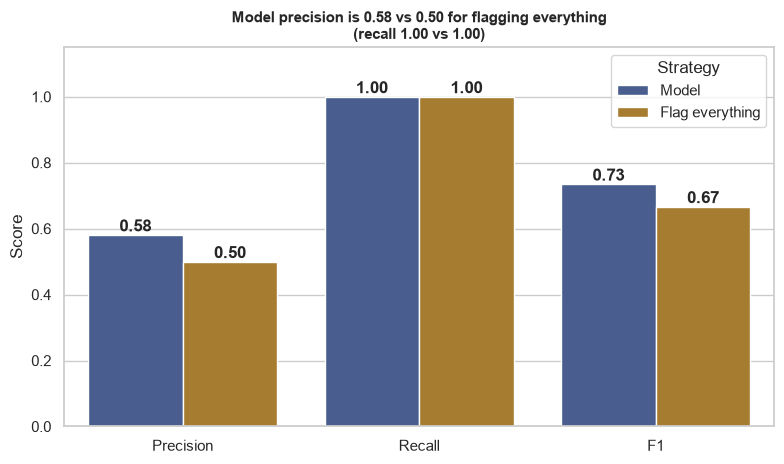

In [4]:
# The same metrics as bars, against the naive "flag everything" strategy
from sklearn.metrics import f1_score
p_m, r_m, f_m = precision_score(y_true, flagged, zero_division=0), recall_score(y_true, flagged), f1_score(y_true, flagged)
p_n = y_true.mean()
cmp = pd.DataFrame({"Metric": ["Precision", "Recall", "F1"] * 2,
                    "Strategy": ["Model"] * 3 + ["Flag everything"] * 3,
                    "Score": [p_m, r_m, f_m, p_n, 1.0, 2 * p_n / (1 + p_n)]})
plt.figure(figsize=(8, 4.8))
ax = sns.barplot(data=cmp, x="Metric", y="Score", hue="Strategy", palette={"Model": BLUE, "Flag everything": AMBER})
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontweight="bold")
story_title(f"Model precision is {p_m:.2f} vs {p_n:.2f} for flagging everything (recall {r_m:.2f} vs 1.00)", size=11)
plt.ylim(0, 1.15); plt.xlabel("")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_vs_baseline.png", dpi=150); plt.show()

### Confusion matrix

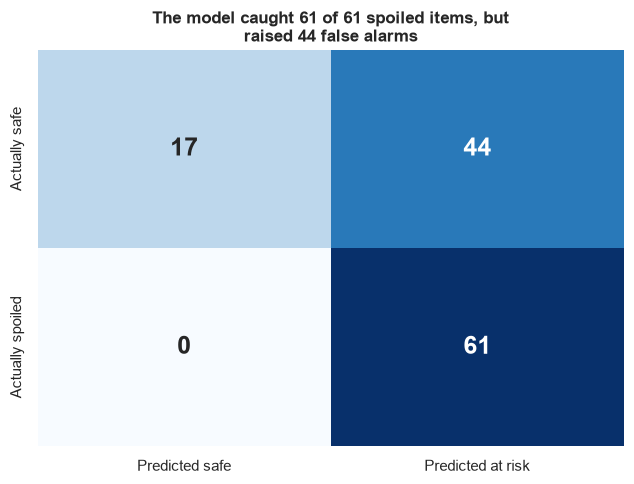

In [5]:
cm = confusion_matrix(y_true, flagged); tn, fp, fn, tp = cm.ravel()
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 18, "weight": "bold"},
            xticklabels=["Predicted safe", "Predicted at risk"], yticklabels=["Actually safe", "Actually spoiled"])
story_title(f"The model caught {tp} of {tp + fn} spoiled items, but raised {fp} false alarms", size=12)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_confusion_matrix.png", dpi=150); plt.show()   # BREAKS IF: only one class in y_true (cm is then not 2x2)

### ROC curve


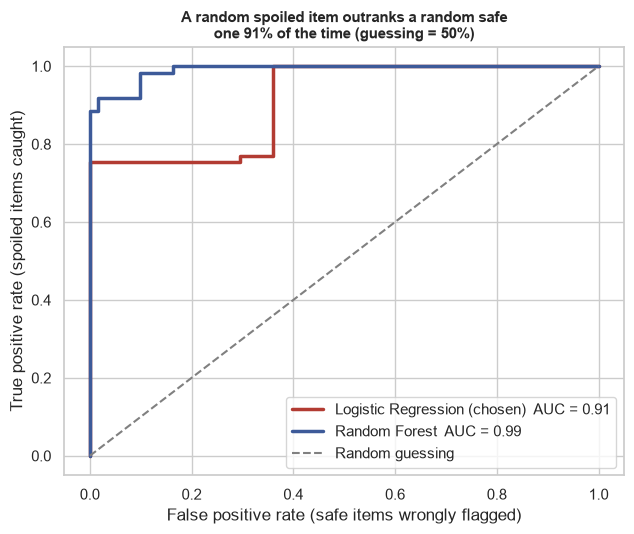

In [6]:
plt.figure(figsize=(6.5, 5.5))
for col, label, colour in [("Final_Prob", f"{MODEL} (chosen)", RED)] + \
        ([("RF_Prob_Raw", "Random Forest", BLUE)] if MODEL != "Random Forest" else [("LR_Prob", "Logistic Regression", BLUE)]):
    fpr, tpr, _ = roc_curve(y_true, test[col]); plt.plot(fpr, tpr, color=colour, linewidth=2.5,
                                                          label=f"{label}  AUC = {roc_auc_score(y_true, test[col]):.2f}")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing")
plt.xlabel("False positive rate (safe items wrongly flagged)"); plt.ylabel("True positive rate (spoiled items caught)")
story_title(f"A random spoiled item outranks a random safe one {roc_auc_score(y_true, prob):.0%} of the time (guessing = 50%)", size=10.5); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_roc_curve.png", dpi=150); plt.show()

### Precision-Recall curve and the chosen threshold
The marker shows where the threshold chosen on **validation** data lands on the **test** curve. The grey line is the naive baseline.

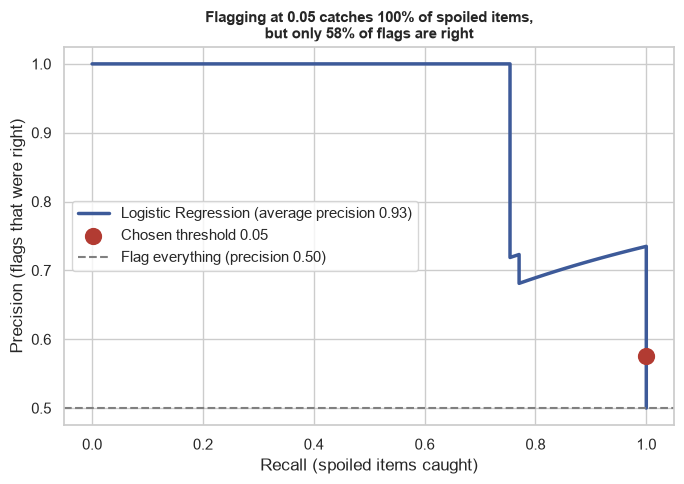

In [7]:
precision, recall, thresholds = precision_recall_curve(y_true, prob)
i = int(np.argmin(np.abs(thresholds - THRESHOLD)))
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color=BLUE, linewidth=2.5, label=f"{MODEL} (average precision {average_precision_score(y_true, prob):.2f})")
plt.scatter(recall[i], precision[i], color=RED, s=130, zorder=5, label=f"Chosen threshold {THRESHOLD:.2f}")
plt.axhline(y_true.mean(), color="grey", linestyle="--", label=f"Flag everything (precision {y_true.mean():.2f})")
plt.xlabel("Recall (spoiled items caught)"); plt.ylabel("Precision (flags that were right)")
story_title(f"Flagging at {THRESHOLD:.2f} catches {recall[i]:.0%} of spoiled items, but only {precision[i]:.0%} of flags are right", size=10.5); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_pr_curve.png", dpi=150); plt.show()

### Feature importance (Random Forest, top 10)

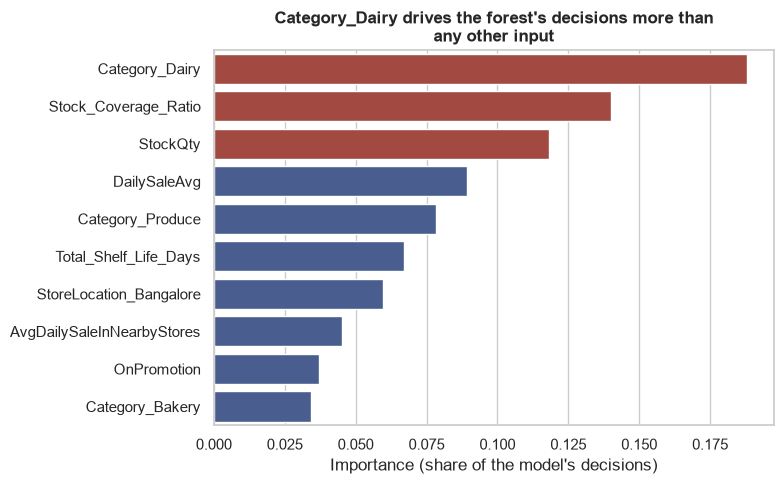

In [8]:
imp = pd.read_csv("../data/interim/rf_feature_importance_v2.csv").head(10)
plt.figure(figsize=(8, 5))
sns.barplot(data=imp, x="Importance", y="Feature", hue="Feature", palette=[RED] * 3 + [BLUE] * 7, legend=False, orient="h")
story_title(f"{imp.iloc[0]['Feature']} drives the forest's decisions more than any other input", size=12)
plt.xlabel("Importance (share of the model's decisions)"); plt.ylabel("")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_feature_importance.png", dpi=150); plt.show()

### Probability distribution (does the model separate the two groups?)
Spoiled items (red) sit to the right of safe items (green). 
Heavy overlap means weak separation.

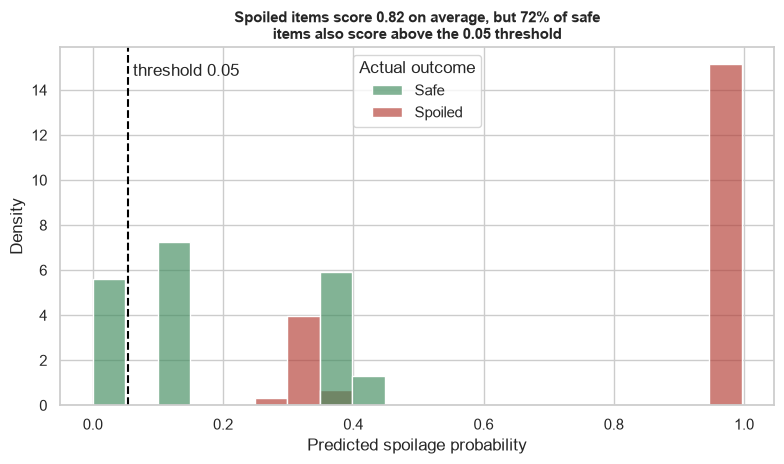

In [9]:
plt.figure(figsize=(8, 4.8))
sns.histplot(x=prob, hue=y_true.map({0: "Safe", 1: "Spoiled"}).rename("Actual outcome"),
             palette={"Safe": GREEN, "Spoiled": RED}, bins=20, alpha=0.65, common_norm=False, stat="density")
plt.axvline(THRESHOLD, color="black", linestyle="--"); plt.text(THRESHOLD, plt.ylim()[1] * 0.92, f" threshold {THRESHOLD:.2f}")
safe_over = (prob[y_true == 0] >= THRESHOLD).mean()
plt.xlabel("Predicted spoilage probability")
story_title(f"Spoiled items score {prob[y_true == 1].mean():.2f} on average, but {safe_over:.0%} of safe items also score above the {THRESHOLD:.2f} threshold", size=11)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_probability_distribution.png", dpi=150); plt.show()

### Business logic
### Priority score
`Priority_Score = StockQty x predicted probability` = expected units at risk. It ranks items by how much stock is on the line, not just by probability.

In [10]:
test["Priority_Score"] = (test["StockQty"] * test["Final_Prob"]).round(1)
top20 = test.sort_values("Priority_Score", ascending=False).head(20)
print("Of the top 20 by Priority_Score, truly spoiled:", int(top20["IsSpoiled"].sum()), "/ 20")
print("Spoiled rate in the test set, for comparison:", round(y_true.mean(), 2))

Of the top 20 by Priority_Score, truly spoiled: 15 / 20
Spoiled rate in the test set, for comparison: 0.5


In [11]:
split = pd.read_csv("../data/interim/smart_waste_split_v2.csv")
dev = split[split["DataSplit"] != "Test"]
base_rate = dev["IsSpoiled"].mean()
rows = []
for gap in [0, -1, -2, -3]:                          # 0 means "any negative gap"
    for q in [0.25, 0.5, 0.75]:
        max_km = dev["DistanceToNearestStore"].quantile(q)
        hit = (dev["Sales_vs_Nearby_Gap"] < gap) & (dev["DistanceToNearestStore"] <= max_km)
        rows.append({"gap_below": gap, "distance_quantile": q, "max_km": round(max_km, 1), "rows_flagged": int(hit.sum()),
                     "precision": round(dev.loc[hit, "IsSpoiled"].mean(), 2) if hit.sum() else np.nan,
                     "spoiled_covered": round(dev.loc[hit, "IsSpoiled"].sum() / dev["IsSpoiled"].sum(), 3)})
grid = pd.DataFrame(rows); print(grid)
ok = grid[grid["precision"] >= base_rate]
best = (ok if len(ok) else grid).sort_values("spoiled_covered", ascending=False).iloc[0]
GAP_CUT, DIST_CUT = float(best["gap_below"]), float(best["max_km"])
print(f"\nBase rate on development rows: {base_rate:.2f}")
print(f"Chosen rule: Sales_vs_Nearby_Gap < {GAP_CUT} AND DistanceToNearestStore <= {DIST_CUT} km")
if not len(ok): print("WARNING: no option beat the base rate, so this cut-off is a convenience, not a validated choice.")

    gap_below  distance_quantile  max_km  rows_flagged  precision  \
0           0               0.25     5.0            59       0.63   
1           0               0.50     8.4           118       0.63   
2           0               0.75    11.7           181       0.64   
3          -1               0.25     5.0            17       0.71   
4          -1               0.50     8.4            47       0.68   
5          -1               0.75    11.7            70       0.64   
6          -2               0.25     5.0             9       0.89   
7          -2               0.50     8.4            19       0.74   
8          -2               0.75    11.7            29       0.69   
9          -3               0.25     5.0             2       1.00   
10         -3               0.50     8.4             5       1.00   
11         -3               0.75    11.7             6       0.83   

    spoiled_covered  
0             0.137  
1             0.273  
2             0.428  
3             

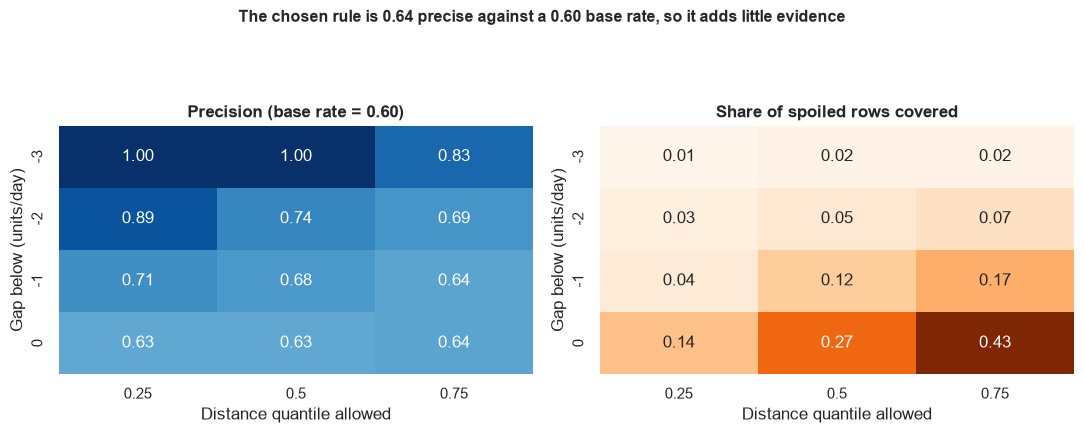

In [12]:
# The redistribution cut-off grid as two heatmaps (left: how precise, right: how much it covers)
prec = grid.pivot(index="gap_below", columns="distance_quantile", values="precision")
cover = grid.pivot(index="gap_below", columns="distance_quantile", values="spoiled_covered")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(prec, annot=True, fmt=".2f", cmap="Blues", center=base_rate, ax=axes[0], cbar=False)
axes[0].set_title(f"Precision (base rate = {base_rate:.2f})", weight="bold")
sns.heatmap(cover, annot=True, fmt=".2f", cmap="Oranges", ax=axes[1], cbar=False)
axes[1].set_title("Share of spoiled rows covered", weight="bold")
for a in axes: a.set_xlabel("Distance quantile allowed"); a.set_ylabel("Gap below (units/day)")
gain = best["precision"] - base_rate
fig.suptitle(textwrap.fill(f"The chosen rule is {best['precision']:.2f} precise against a {base_rate:.2f} base rate, so it adds " + ("little evidence" if gain < 0.10 else "some evidence"), 95),
             fontsize=11.5, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.88]); plt.savefig(f"{FIG_DIR}/eval_redistribution_grid.png", dpi=150); plt.show()

### Final recommended action
One probability threshold for everything:
* below the threshold -> **Normal**
* at/above the threshold and the redistribution rule applies -> **Redistribute** (move it to a store that sells it faster)
* at/above the threshold otherwise -> **Discount/Promotion**

Redistribution only applies to items already flagged as at risk. We do not move stock that is not in danger.

In [13]:
test["Redistribution_Candidate"] = (test["Sales_vs_Nearby_Gap"] < GAP_CUT) & (test["DistanceToNearestStore"] <= DIST_CUT)
at_risk = test["Final_Prob"] >= THRESHOLD
test["Recommended_Action"] = np.where(at_risk & test["Redistribution_Candidate"], "Redistribute",
                              np.where(at_risk, "Discount/Promotion", "Normal"))
print(test["Recommended_Action"].value_counts())

Recommended_Action
Discount/Promotion    72
Redistribute          33
Normal                17
Name: count, dtype: int64


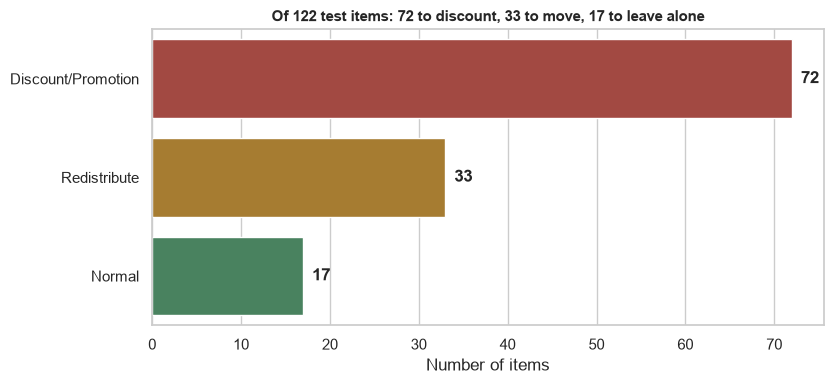

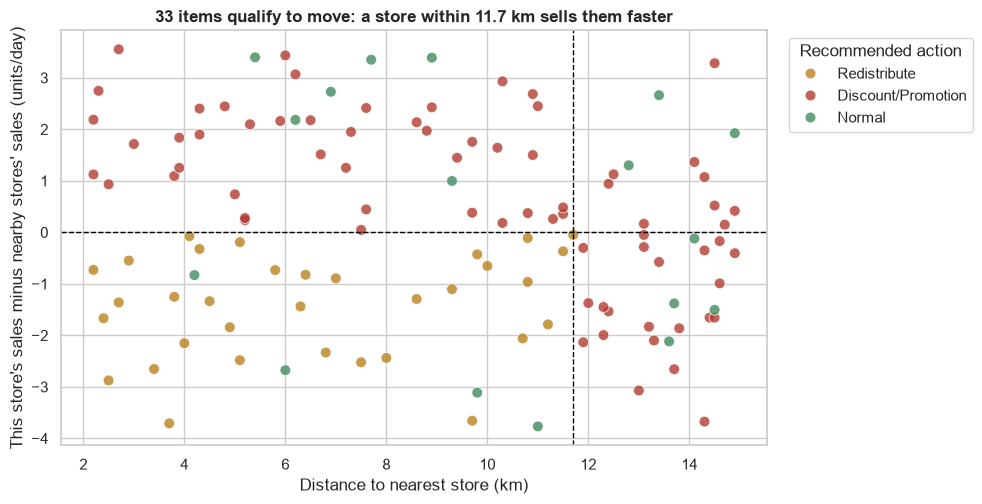

In [14]:
# VISUAL 1: how many items get each action
counts = test["Recommended_Action"].value_counts().reindex(["Discount/Promotion", "Redistribute", "Normal"]).fillna(0)
plt.figure(figsize=(8.5, 4))
ax = sns.barplot(x=counts.values, y=counts.index, hue=counts.index, palette=[RED, AMBER, GREEN], legend=False, orient="h")
for i, v in enumerate(counts.values): ax.text(v + 1, i, f"{int(v)}", va="center", fontweight="bold")
plt.title(f"Of {len(test)} test items: {int(counts['Discount/Promotion'])} to discount, {int(counts['Redistribute'])} to move, {int(counts['Normal'])} to leave alone",
          fontsize=11, weight="bold")
plt.xlabel("Number of items"); plt.ylabel("")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_action_counts.png", dpi=150); plt.show()

# VISUAL 2 : The redistribution rule made visible. Each dot is an item; dashed lines are the two cut-offs.
plt.figure(figsize=(10, 5.2))
sns.scatterplot(data=test, x="DistanceToNearestStore", y="Sales_vs_Nearby_Gap", hue="Recommended_Action",
                palette={"Discount/Promotion": RED, "Redistribute": AMBER, "Normal": GREEN}, alpha=0.8, s=60)
plt.axhline(GAP_CUT, color="black", linestyle="--", linewidth=1); plt.axvline(DIST_CUT, color="black", linestyle="--", linewidth=1)
n_move = int((test["Recommended_Action"] == "Redistribute").sum())
story_title(f"{n_move} items qualify to move: a store within {DIST_CUT:.1f} km sells them faster", size=12)
plt.xlabel("Distance to nearest store (km)"); plt.ylabel("This store's sales minus nearby stores' sales (units/day)")
plt.legend(title="Recommended action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_redistribution_scatter.png", dpi=150); plt.show()

#### Business impact
**Units come from the data. Price, markdown and effectiveness are assumptions**, because the dataset has no prices. The 21% effectiveness comes from the dynamic-pricing study cited in the literature review.

In [15]:
exposed = int(test.loc[test["IsSpoiled"] == 1, "StockQty"].sum())
caught = int(test.loc[(test["IsSpoiled"] == 1) & (test["Final_Pred"] == 1), "StockQty"].sum())
needless = int(test.loc[(test["IsSpoiled"] == 0) & (test["Final_Pred"] == 1), "StockQty"].sum())
print(f"Units in test batches that spoiled : {exposed:,}")
print(f"Units flagged in time              : {caught:,}")
print(f"Units flagged needlessly (false alarms): {needless:,}")

UNIT_PRICE = 20.0      # ASSUMPTION (pula per unit): replace with a justified average shelf price
MARKDOWN = 0.30        # ASSUMPTION: discount applied to units flagged needlessly
needless_cost = needless * MARKDOWN * UNIT_PRICE
for effect in [0.10, 0.21, 0.50]:     # share of flagged-in-time units actually saved by acting
    saved = caught * effect
    print(f"If acting saves {effect:.0%}: {saved:,.0f} units = P{saved * UNIT_PRICE:,.0f} saved, minus P{needless_cost:,.0f} markdown cost on false alarms = P{saved * UNIT_PRICE - needless_cost:,.0f} net")
if caught:
    print(f"Break-even effectiveness: {needless_cost / (caught * UNIT_PRICE):.0%} of flagged-in-time units must be saved just to cover the false-alarm markdowns")

Units in test batches that spoiled : 7,246
Units flagged in time              : 7,246
Units flagged needlessly (false alarms): 9,262
If acting saves 10%: 725 units = P14,492 saved, minus P55,572 markdown cost on false alarms = P-41,080 net
If acting saves 21%: 1,522 units = P30,433 saved, minus P55,572 markdown cost on false alarms = P-25,139 net
If acting saves 50%: 3,623 units = P72,460 saved, minus P55,572 markdown cost on false alarms = P16,888 net
Break-even effectiveness: 38% of flagged-in-time units must be saved just to cover the false-alarm markdowns


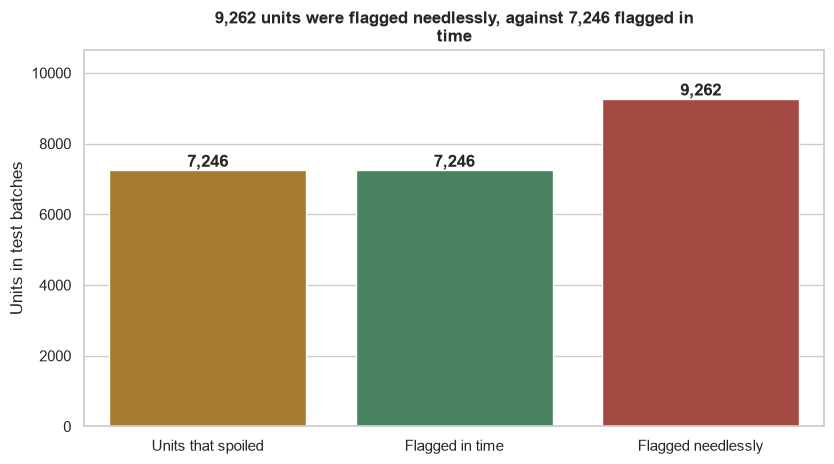

In [16]:
# Units in the test batches, in plain bars
units = pd.DataFrame({"Group": ["Units that spoiled", "Flagged in time", "Flagged needlessly"], "Units": [exposed, caught, needless]})
plt.figure(figsize=(8.5, 4.8))
ax = sns.barplot(data=units, x="Group", y="Units", hue="Group", palette=[AMBER, GREEN, RED], legend=False)
for c in ax.containers: ax.bar_label(c, fmt="{:,.0f}", fontweight="bold")
story_title(f"{needless:,} units were flagged needlessly, against {caught:,} flagged in time", size=12)
plt.xlabel(""); plt.ylabel("Units in test batches"); plt.ylim(0, max(units["Units"]) * 1.15)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_units_impact.png", dpi=150); plt.show()

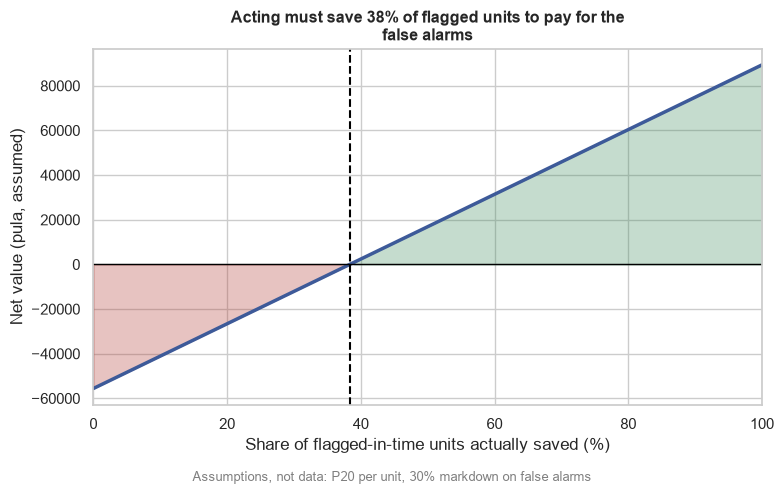

In [17]:
# Break-even chart (assumption-based)
if caught:
    effect = np.linspace(0, 1, 101); net = caught * UNIT_PRICE * effect - needless_cost
    be = needless_cost / (caught * UNIT_PRICE)
    plt.figure(figsize=(8, 4.8)); plt.plot(effect * 100, net, color=BLUE, linewidth=2.5)
    plt.fill_between(effect * 100, net, 0, where=(net >= 0), color=GREEN, alpha=0.3)
    plt.fill_between(effect * 100, net, 0, where=(net < 0), color=RED, alpha=0.3)
    plt.axhline(0, color="black", linewidth=1)
    if be <= 1: plt.axvline(be * 100, color="black", linestyle="--")   # only draw break-even if it is reachable
    plt.xlim(0, 100)
    story_title(f"Acting must save {be:.0%} of flagged units to pay for the false alarms" if be <= 1 else f"Even saving every flagged unit would not cover the false alarms (break-even would be {be:.0%})", size=11.5)
    plt.xlabel("Share of flagged-in-time units actually saved (%)"); plt.ylabel("Net value (pula, assumed)")
    plt.figtext(0.5, -0.02, f"Assumptions, not data: P{UNIT_PRICE:.0f} per unit, {MARKDOWN:.0%} markdown on false alarms", ha="center", fontsize=9, color="grey")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval_break_even.png", dpi=150, bbox_inches="tight"); plt.show()

In [18]:
lookup = pd.read_csv("../data/interim/display_lookup_v2.csv")
out = test.merge(lookup, on="RowID", how="left")

out["Nearby_Demand_Gap"] = (-out["Sales_vs_Nearby_Gap"]).round(1)       # positive = a nearby store sells it faster
out["RF_Prob"] = out["Final_Prob"].round(3)                              # alias: final model's probability
out["RF_Pred"] = out["Final_Pred"]                                       # alias: final model's prediction
for col in ["IsSpoiled", "OnPromotion", "TemperatureSensitive"]:         # back to True/False for Power BI
    out[col] = out[col].astype(bool)

dash_cols = ["ItemName", "Brand", "Category", "StoreLocation", "StoreID", "Zone", "ArrivalDate", "ExpiryDate",
             "DaysUntilExpiry", "StockQty", "DailySaleAvg", "OnPromotion", "TemperatureSensitive", "IsSpoiled",
             "RF_Prob", "RF_Pred", "Priority_Score", "Redistribution_Candidate", "Sales_vs_Nearby_Gap",
             "DistanceToNearestStore", "Nearby_Demand_Gap", "Recommended_Action", "DataSplit", "Model_Used", "Threshold"]
out[dash_cols].to_csv("../outputs/powerbi/smart_waste_dashboard_data_v2.csv", index=False)
print("Saved", len(out), "test rows -> ../outputs/powerbi/smart_waste_dashboard_data_v2.csv")
print(out["Recommended_Action"].value_counts().to_dict())
out[dash_cols].head()

Saved 122 test rows -> ../outputs/powerbi/smart_waste_dashboard_data_v2.csv
{'Discount/Promotion': 72, 'Redistribute': 33, 'Normal': 17}


,ItemName,Brand,Category,StoreLocation,StoreID,Zone,ArrivalDate,ExpiryDate,DaysUntilExpiry,StockQty,...,RF_Pred,Priority_Score,Redistribution_Candidate,Sales_vs_Nearby_Gap,DistanceToNearestStore,Nearby_Demand_Gap,Recommended_Action,DataSplit,Model_Used,Threshold
0,Mother Dairy Butter 100g,Mother Dairy,Dairy,Kanpur,Kanpur_3,Unknown,2025-06-19,2025-06-23,0.5,220,...,1,26.1,True,-0.047221,11.7,0.0,Redistribute,Test,Logistic Regression,0.054057
1,Mother Dairy Butter 100g,Mother Dairy,Dairy,Kanpur,Kanpur_20,Unknown,2025-06-19,2025-06-23,0.5,220,...,1,24.6,False,0.417504,14.9,-0.4,Discount/Promotion,Test,Logistic Regression,0.054057
2,Mother Dairy Butter 100g,Mother Dairy,Dairy,Kanpur,Kanpur_50,Unknown,2025-06-19,2025-06-23,0.5,220,...,1,28.8,True,-0.823431,6.4,0.8,Redistribute,Test,Logistic Regression,0.054057
3,Mother Dairy Butter 100g,Mother Dairy,Dairy,Kanpur,Kanpur_67,Unknown,2025-06-19,2025-06-23,0.5,220,...,1,25.7,False,-0.575960,13.4,0.6,Discount/Promotion,Test,Logistic Regression,0.054057
4,Mother Dairy Butter 100g,Mother Dairy,Dairy,Kanpur,Kanpur_92,Unknown,2025-06-19,2025-06-23,0.5,220,...,1,25.6,False,1.500927,10.9,-1.5,Discount/Promotion,Test,Logistic Regression,0.054057
